## Lab: Market Return Dynamics

We will repeat the weather analysis using the stock market's daily percentage change, recorded in `market_return_pct` in `ff_market_daily.parquet`.

- **2** means the market gained 2% that day.
- **−2** means the market lost 2%.
- **0** means no change.

Use `market_return_pct` as it is. Each row is one trading day, so the next row is the next day the market was open.

**Does today's category help predict the next trading day's category?**


In [1]:
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import pandas as pd 

df = pd.read_parquet('../data/ff_market_daily.parquet')
df['date'] = pd.to_datetime(df['date'])
df = df.sort_values('date').reset_index(drop=True)

print(f"{len(df):,} trading-day observations: "
      f"{df['date'].min():%Y-%m-%d} to {df['date'].max():%Y-%m-%d}")
print(f"Are dates ordered? {df['date'].is_monotonic_increasing}")
df[['date', 'market_return_pct']].head()

26,296 trading-day observations: 1926-07-01 to 2026-07-31
Are dates ordered? True


,date,market_return_pct
0,1926-07-01,0.10
1,1926-07-02,0.46
2,1926-07-06,0.18
3,1926-07-07,0.10
4,1926-07-08,0.23


Here are plots of `market_return_pct`, as a kernel density plot and a time series.

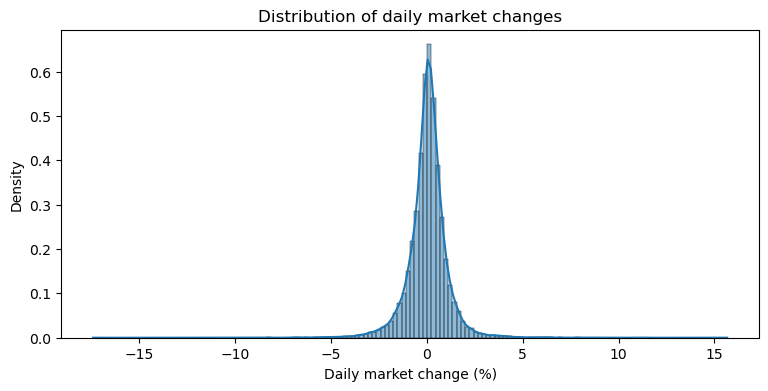

In [2]:
fig, ax = plt.subplots(figsize=(9, 4))
sns.histplot(data=df, x='market_return_pct', bins=150, stat='density', kde=True, ax=ax)
ax.set(xlabel='Daily market change (%)', title='Distribution of daily market changes')
plt.show()

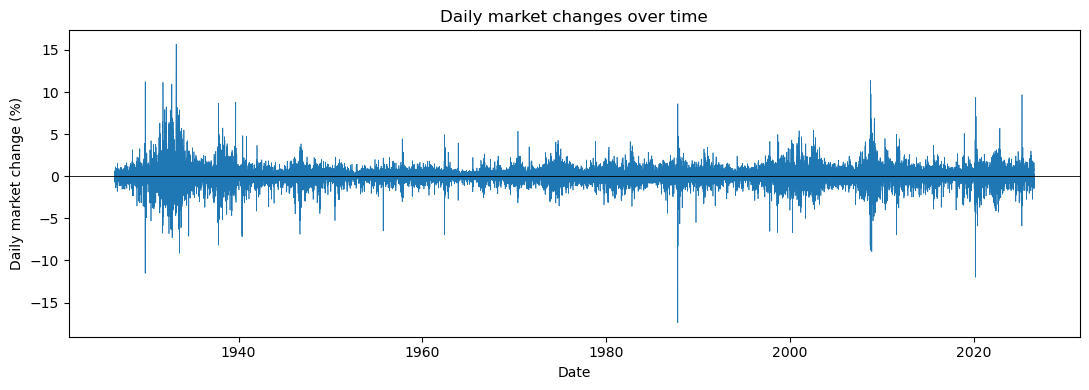

In [3]:
fig, ax = plt.subplots(figsize=(11, 4))
ax.plot(df['date'], df['market_return_pct'], linewidth=0.5)
ax.axhline(0, color='black', linewidth=0.6)
ax.set(xlabel='Date', ylabel='Daily market change (%)',
       title='Daily market changes over time')
fig.tight_layout()
plt.show()

### 1. Part One: Two States

- Start with two categories: **Up** for values greater than 0, and **Down (and flat)** for values less than or equal to 0. Create variables in your dataframe to capture the current and next value of `market_return_pct`.
- Pair today's category with the next trading day's category. Compute the joint PMF and marginals, and the conditional PMF. 
- Are up transitions more or less common than down transitions? 
- Are you more likely to transition to an Up day from a Down or Up day?

In [4]:
# make a categorical column "direction_t" 
df['direction_t'] = ['Up' if x > 0 else 'Down' for x in df['market_return_pct']]
#did this before we did in class, I checked it and it worked so I'll stick with it

In [5]:
# make a categorical column "direction_tp1" for the next trading day
df['direction_tp1'] = df['direction_t'].shift(-1)

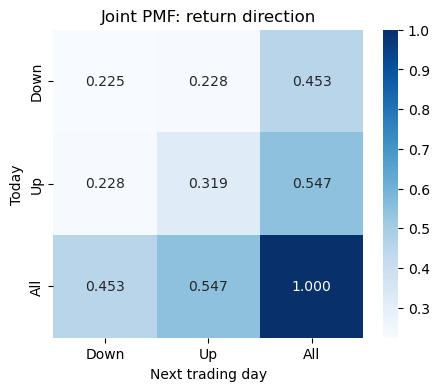

In [6]:
# Plot the joint PMF
fig, ax = plt.subplots(figsize=(5, 4))
sns.heatmap(pd.crosstab(df['direction_t'], df['direction_tp1'], normalize=True, margins=True),
            annot=True, fmt='.3f', cmap='Blues', ax=ax)
ax.set(xlabel='Next trading day', ylabel='Today', title='Joint PMF: return direction')
plt.show()

In [7]:
# Plot the conditional PMF
pd.crosstab(df['direction_t'], df['direction_tp1'], normalize='index')

direction_tp1,Down,Up
direction_t,,
Down,0.496221,0.503779
Up,0.416974,0.583026


<div class='alert alert-info'><b>Answer the following:</b>

- Are up transitions more or less common than down transitions? 
- Are you more likely to transition to an Up day from a Down or Up day?

</div>

- Up transitions are more common than down transitions since they are more common both today and tomorrow
- More likely to transition from an up to an up (.58 vs .50)

### 2. Binning a Continuous Variable

Now keep the sign and a coarse measure of the size of a daily log return:

| Category | Daily log return (%) |
| --- | --- |
| Large loss | $r \leq -1$ |
| Small loss | $-1 < r \leq -0.1$ |
| Near zero | $-0.1 < r \leq 0.1$ |
| Small gain | $0.1 < r \leq 1$ |
| Large gain | $r > 1$ |

For example, −2 belongs to **Large loss**, 0.05 to **Near zero**, and 0.8 to **Small gain**. These cutoffs are choices for this exercise. Each interval includes its upper endpoint; `-np.inf` and `np.inf` let the outer intervals include any size loss or gain.

- `pd.cut` to group `market_return_pct` into the five categories above. How many days fall into each of the five bins? Which are the most or least common?
- Compute the joint PMF and marginals. Which transitions are most likely to occur? 
- Compute the conditional PMF. For each current state, which two future states are the most likely? Subjectively, how close is each row to a uniform mass function with probability .2 over each transition? Is it relatively easy or difficult to predict the next state?
- Subtract the marginal PMF of tomorrow's state from each row of the conditional PMF, and plot the result as a heatmap. If tomorrow's state were independent of today's, every row of the conditional PMF would equal this marginal. Which transitions are more likely than independence predicts, and which are less likely? Does knowing today's state change the forecast for tomorrow?
- For each state, compute the conditional expectation of tomorrow's `market_return_pct`. Given the current state, what are the expected percent returns for tomorrow? How do the min and max values for tomorrow vary across states? Which states have the highest standard deviation for tomorrow's percent returns? Describe any patterns in the volatility you notice. Using `.groupby` and `.describe` is the easiest way to do this. 

In [8]:
return_categories = ['Large loss', 'Small loss', 'Near zero', 'Small gain', 'Large gain']
df['return_bin'] = pd.cut(df['market_return_pct'], bins=[-np.inf, -1, -0.1, 0.1, 1, np.inf], labels=return_categories)
df.head()


,date,year,month,month_start,trading_day_of_month,mkt_excess_return_pct,risk_free_return_pct,market_return_pct,absolute_market_return_pct,direction_t,direction_tp1,return_bin
0,1926-07-01,1926,7,1926-07-01,1,0.09,0.01,0.10,0.10,Up,Up,Near zero
1,1926-07-02,1926,7,1926-07-01,2,0.45,0.01,0.46,0.46,Up,Up,Small gain
2,1926-07-06,1926,7,1926-07-01,3,0.17,0.01,0.18,0.18,Up,Up,Small gain
3,1926-07-07,1926,7,1926-07-01,4,0.09,0.01,0.10,0.10,Up,Up,Near zero
4,1926-07-08,1926,7,1926-07-01,5,0.22,0.01,0.23,0.23,Up,Down,Small gain


In [9]:
#make y_t and y_tp1 columns for the return bins

df['y_t'] = df['return_bin']
df['y_tp1'] = df['return_bin'].shift(-1)

<div class='alert alert-info'><b>Answer the following:</b>

- How many days fall into each of the five bins?  (use value_counts)
- Which are the most or least common?
  
  </div>

In [10]:
display(df['y_t'].value_counts())
pd.crosstab(df['y_t'], df['y_tp1'], margins=True, normalize=True)

y_t
Small gain    9785
Small loss    7452
Near zero     3441
Large gain    2859
Large loss    2759
Name: count, dtype: int64

y_tp1,Large loss,Small loss,Near zero,Small gain,Large gain,All
y_t,,,,,,
Large loss,0.021335,0.027191,0.009051,0.027800,0.019547,0.104925
Small loss,0.035444,0.088648,0.034151,0.097775,0.027382,0.283400
Near zero,0.009317,0.041985,0.020955,0.049325,0.009279,0.130861
Small gain,0.024986,0.100057,0.055029,0.159422,0.032592,0.372086
Large gain,0.013843,0.025518,0.011637,0.037802,0.019928,0.108728
All,0.104925,0.283400,0.130823,0.372124,0.108728,1.000000


- Bins printed above
- Small gains are the most common by far

<div class='alert alert-info'><b>Answer the following:</b>

Which transitions are most likely to occur? 

</div>

A small gain into a small gain is the most likely transition at 0.428

In [11]:
#conditional PMF 
pd.crosstab(df['y_t'], df['y_tp1'], normalize='index', margins=True)

y_tp1,Large loss,Small loss,Near zero,Small gain,Large gain
y_t,,,,,
Large loss,0.203335,0.259152,0.086263,0.264951,0.186299
Small loss,0.125067,0.312802,0.120505,0.345008,0.096618
Near zero,0.071200,0.320837,0.160128,0.376925,0.070910
Small gain,0.067150,0.268908,0.147895,0.428455,0.087592
Large gain,0.127317,0.234697,0.107030,0.347674,0.183281
All,0.104925,0.283400,0.130823,0.372124,0.108728


<div class='alert alert-info'><b>Answer the following:</b>

- For each current state, which two future states are the most likely? 
- Subjectively, how close is each row to a uniform mass function with probability .2 over each transition? 
- Is it relatively easy or difficult to predict the next state?
</div>

- Large loss -> small loss, large loss; Small loss -> small gain, small loss; Near zero -> small gain, small loss; Small gain -> small gain, small loss; Large gain -> small gain, small loss. 
- Not very close. Seems like it's much more likely that t+1 is a small gain or small loss nearly regardless of what t is
- I wouldn't call it easy since 0.428 is the highest probability in the joint pmf, so there's not a lot of certainty in predicting with only teh current state

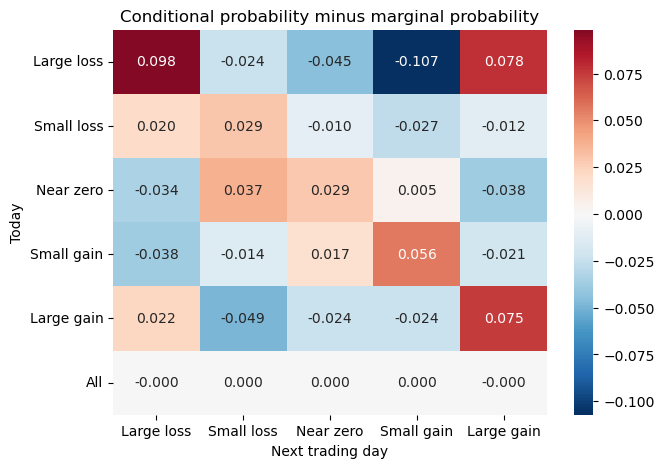

In [12]:
# marginal PMF of tomorrow's state: sum the joint PMF (without margins) down each column
next_state_pmf = pd.crosstab(df['y_t'], df['y_tp1'], normalize=True).sum(axis=0)
conditional = pd.crosstab(df['y_t'], df['y_tp1'], normalize='index', margins=True)
# subtract it from each row of the conditional PMF and plot as a heatmap
# hint: use .sub(next_state_pmf, axis='columns'), and a diverging colormap such as cmap='RdBu_r' with center=0
fig, ax = plt.subplots(figsize = (7, 5))
sns.heatmap(
    conditional.sub(next_state_pmf, axis='columns'), 
    annot=True, fmt='.3f', center=0, cmap='RdBu_r', ax=ax
)
ax.set(xlabel='Next trading day', ylabel='Today', 
       title = 'Conditional probability minus marginal probability')
plt.show()

<div class='alert alert-info'><b>Answer the following:</b>

- Which transitions are more likely than independence predicts, and which are less likely?
- Does knowing today's state change the forecast for tomorrow?
- How is this comparison different from comparing each row to a uniform PMF with probability .2?
</div>

- More likely: Large loss to (large loss, large gain), Small loss to (large loss, small loss), Zero to (small loss, zero, small gain), Small gain to (zero, small gain), Large gain to (Large loss, large gain); Less likely: Large loss to (small loss, zero, small gain), Small loss to (zero, small gain, large gain), Zero to (large loss, large gain), Small gain to (large loss, small loss, large gain), Large gain to (small loss, zero, small gain)
- Slightly yes. The large gains/losses are often followed by other large gains/losses while the smaller moves are grouped next to other smaller moves
- The comparing to the uniform doesn't reflect how commonly these transitions happen 

In [13]:
df['market_return_pct_tp1'] = df['market_return_pct'].shift(-1)
# use groupby and describe/mean to get the conditional expectation of the next day's return given today's return bin y_t
df.groupby('y_t')['market_return_pct_tp1'].describe()

C:\Users\hodag\AppData\Local\Temp\ipykernel_3328\2658844929.py:3: FutureWarning: The default of observed=False is deprecated and will be changed to True in a future version of pandas. Pass observed=False to retain current behavior or observed=True to adopt the future default and silence this warning.
  df.groupby('y_t')['market_return_pct_tp1'].describe()


,count,mean,std,min,25%,50%,75%,max
y_t,,,,,,,,
Large loss,2759.0,-0.038311,1.720570,-17.41,-0.79,-0.01,0.72,11.22
Small loss,7452.0,-0.043814,1.009529,-11.23,-0.53,0.01,0.45,11.36
Near zero,3441.0,0.015013,0.826054,-8.19,-0.35,0.03,0.42,5.49
Small gain,9784.0,0.106810,0.832186,-8.25,-0.25,0.12,0.50,8.67
Large gain,2859.0,0.163092,1.384086,-12.00,-0.37,0.15,0.73,15.67


<div class='alert alert-info'><b>Answer the following:</b>

- Given the current state, what are the expected percent returns for tomorrow? 
- How do the min and max values for tomorrow vary across states? 
- Which states have the highest standard deviation for tomorrow's percent returns? 
- Describe any patterns in the volatility you notice.
</div>


- The expected returns for tomorrow given today is the mean of whatever today's state is
- The min and max are more extreme when day t was either a large loss or gain
- Large loss and gain have the largest std in tomorrows returns
- Large losses and gains are more likely to be followed by large losses or gains, meaning that the market tends to stay in its current state of unstable or stable

### 3. Scaling up

The choice of five bins was arbitrary. For more realistic or complex models, we'd want to flexibly choose the number of bins. Instead of the five bins from above, we'll break the data into 21 equally spaced bins based on quantile; the qualitative results hold up for 11 or 71 or 101, but 21 is interpretable and easier to manage.

- Use `pd.qcut` to assign the data into 21 bins, and add that variable to the dataframe as `df[y_t]`. Use `.shift(-1)` to create `df[y_tp1]`. 
- Compute the joint PMF. Plot it as a heatmap. Do you see any obvious patterns? Explain. Try subtracting 1/21**2 from the PMF before plotting it, to normalize away the uniform PMF, and see systematic deviations from uniformly random behavior.
- Compute the conditional PMF. Plot it as a heatmap. Do you see any obvious patterns? Explain. Try subtracting 1/21 from the PMF before plotting it, to normalize away the uniform PMF, and see systematic deviations from uniformly random transitions.
- For each bin, compute the next day's minimum, mean, and maximum values. Plots these as lines on a graph against the bins. Do you see any obvious patterns? Explain. 
- For each bin, compute the next day's standard deviation, and plot it as a line graph against the bins. Do you see any obvious patterns? Explain. 
- How easy is it to predict the market?

In [14]:
#cut into 21 equal-sized bins and make y_t and y_tp1 columns for the return bins
bins = 21
labels = [f"Q{i+1}" for i in range(bins)]

df['y_t'] = pd.qcut(df['market_return_pct'], q=bins, labels=labels)
df['y_tp1'] = df['y_t'].shift(-1)

df['y_t'].value_counts(sort=False).rename('Trading days').to_frame().T

y_t,Q1,Q2,Q3,Q4,Q5,Q6,Q7,Q8,Q9,Q10,...,Q12,Q13,Q14,Q15,Q16,Q17,Q18,Q19,Q20,Q21
Trading days,1255,1253,1286,1280,1230,1226,1371,1206,1198,1331,...,1223,1294,1223,1310,1193,1211,1283,1225,1250,1238


<Axes: xlabel='y_tp1', ylabel='y_t'>

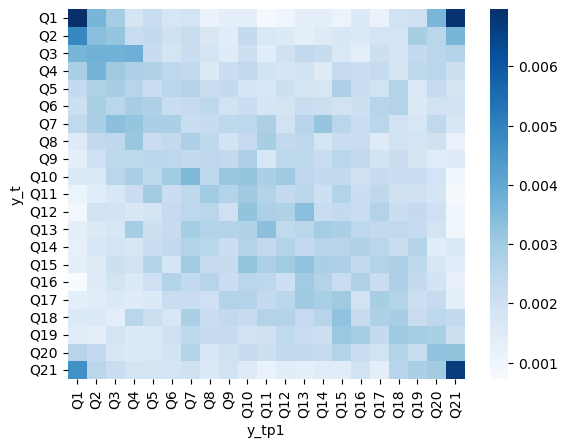

In [15]:
#joint PMF with marginals for the 21 quantile bins + plot as heatmap
quantile_joint = pd.crosstab(
    df['y_t'], df['y_tp1'], normalize=True, margins=False
)
sns.heatmap(quantile_joint, cmap='Blues')

<Axes: xlabel='y_tp1', ylabel='y_t'>

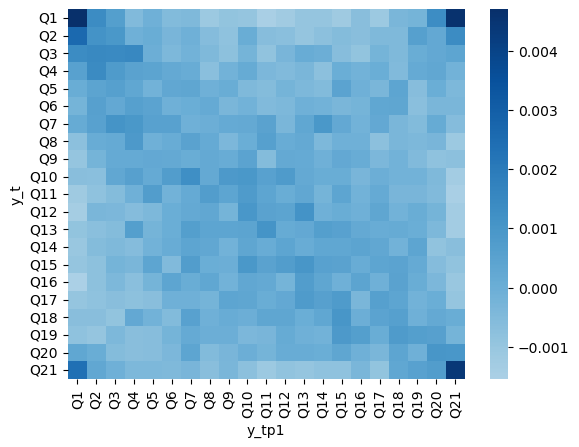

In [16]:
# Subtract 1/21**2 from the PMF before plotting it, to normalize away the uniform PMF, 
# and see systematic deviations from uniformly random behavior.
sns.heatmap(quantile_joint - 1/bins**2, cmap='Blues', center=0)

<div class='alert alert-info'><b>Answer the following:</b>

Do you see any obvious patterns?

</div>

- There's a sort of X shape among the joint pmf that's really accentuated towards the tips, which gives me 2 conclusions: Extremely large gains and losses are followed by the same, and extremely large gains and losses on day t means day tp1 will likely not go back to smaller gains or losses, rather work its way back gradually

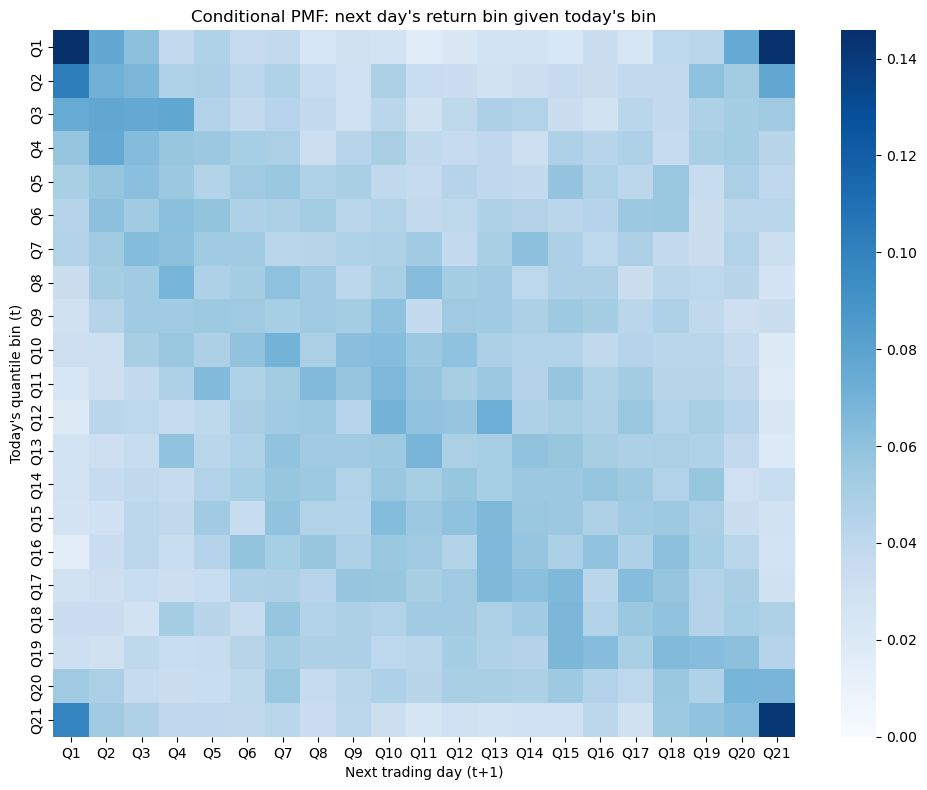

In [22]:
# compute and plot the conditional
quantile_conditional = pd.crosstab(
    df['y_t'], df['y_tp1'], normalize='index'
)

fig, ax = plt.subplots(figsize=(10, 8))
sns.heatmap(
    quantile_conditional,
    cmap='Blues',
    vmin=0,
    vmax=quantile_conditional.to_numpy().max(),
    ax=ax
)
ax.set(
    xlabel="Next trading day (t+1)",
    ylabel="Today's quantile bin (t)",
    title="Conditional PMF: next day's return bin given today's bin"
)
fig.tight_layout()
plt.show()


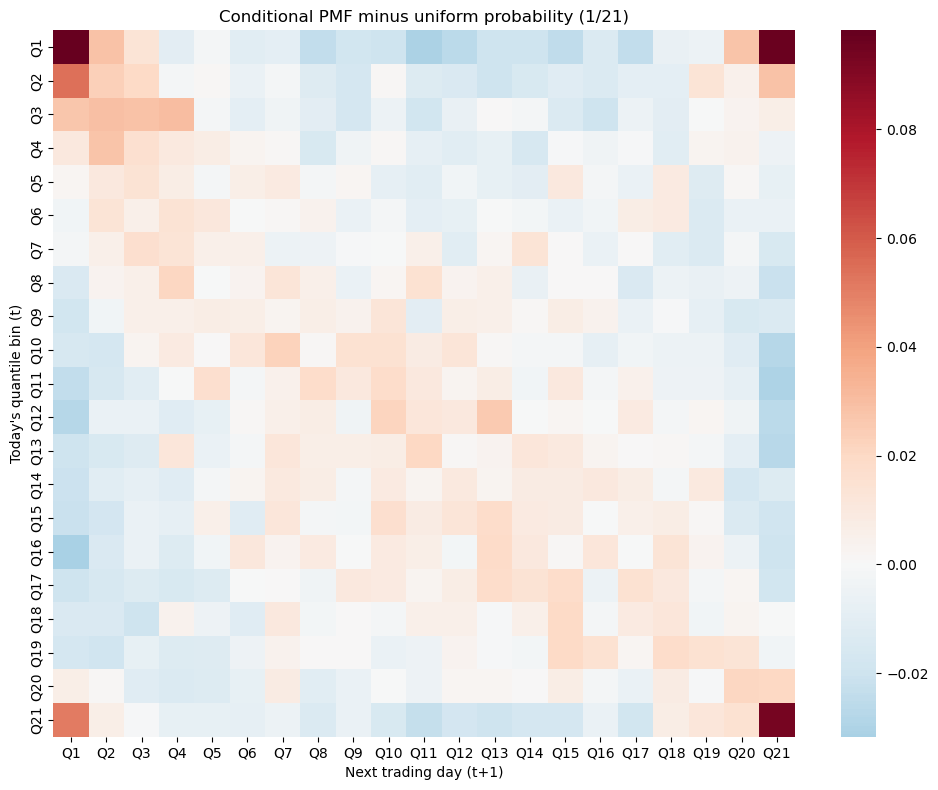

In [23]:
# Subtract 1/21**2 from the PMF before plotting it, to normalize away the uniform PMF, 
# and see systematic deviations from uniformly random behavior.
fig, ax = plt.subplots(figsize=(10, 8))
sns.heatmap(
    quantile_conditional - 1 / bins,
    cmap='RdBu_r',
    center=0,
    annot=False,
    ax=ax
)
ax.set(
    xlabel="Next trading day (t+1)",
    ylabel="Today's quantile bin (t)",
    title="Conditional PMF minus uniform probability (1/21)"
)
fig.tight_layout()
plt.show()

<div class='alert alert-info'><b>Answer the following:</b>

Do you see any obvious patterns?

</div>

- Very similar to the joint pmf where there's the X pattern thats accentuated in the corners. Same conclusions from that as well.

In [24]:
# Compute tomorrow's minimum, mean, and maximum return conditional on today's bin
next_return_summary = (
    df.groupby('y_t', observed=False)['market_return_pct_tp1']
      .agg(min='min', mean='mean', max='max')
      .reindex(labels)
)
display(next_return_summary)

,min,mean,max
y_t,,,
Q1,-17.41,-0.013713,11.22
Q2,-7.36,-0.076712,6.36
Q3,-8.79,-0.097084,11.36
Q4,-8.28,-0.058594,6.16
Q5,-6.89,-0.024211,4.56
Q6,-11.23,-0.022692,6.37
Q7,-3.94,-0.030241,7.37
Q8,-3.40,-0.014303,4.76
Q9,-6.00,0.025860,5.49


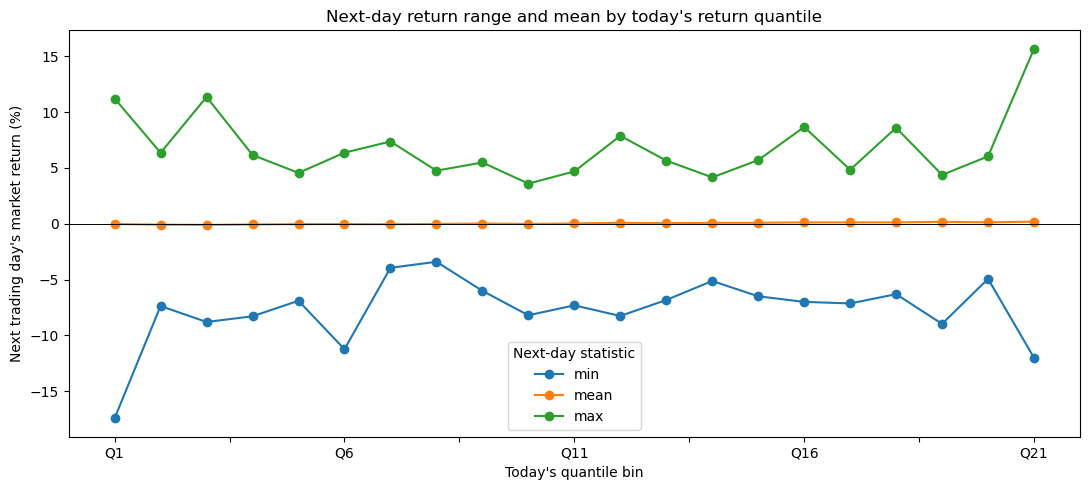

In [25]:
#plot as lines on a graph against the bins
fig, ax = plt.subplots(figsize=(11, 5))
next_return_summary.plot(ax=ax, marker='o')
ax.axhline(0, color='black', linewidth=0.7)
ax.set(
    xlabel="Today's quantile bin",
    ylabel="Next trading day's market return (%)",
    title="Next-day return range and mean by today's return quantile"
)
ax.legend(title="Next-day statistic")
fig.tight_layout()
plt.show()

<div class='alert alert-info'><b>Answer the following:</b>

Do you see any obvious patterns?

</div>

- Market is more stable around 0 and behaves more erratically following large gains/losses

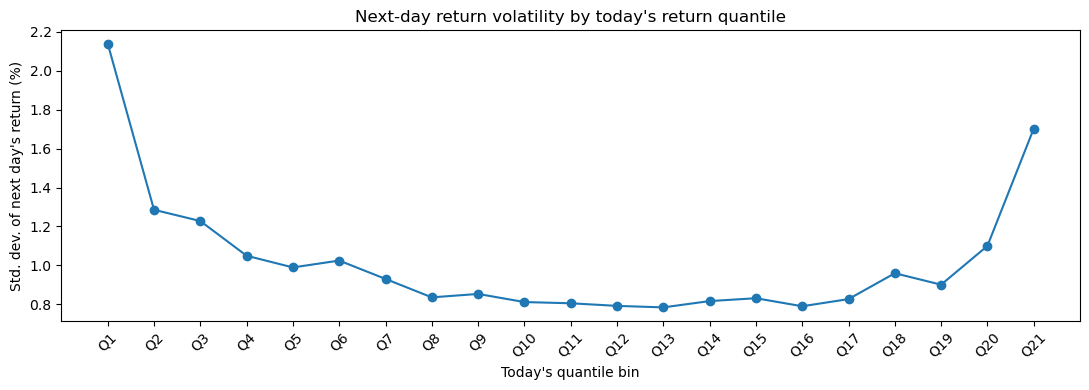

,Next-day return standard deviation
y_t,
Q1,2.140465
Q2,1.285882
Q3,1.227976
Q4,1.049607
Q5,0.989470
Q6,1.024761
Q7,0.930389
Q8,0.835663
Q9,0.853220


In [26]:
#compute the next day's standard deviation, and plot it as a line graph against the bins. 
next_return_std = (
    df.groupby('y_t', observed=False)['market_return_pct_tp1']
      .std()
      .reindex(labels)
)

fig, ax = plt.subplots(figsize=(11, 4))
ax.plot(labels, next_return_std, marker='o')
ax.set(
    xlabel="Today's quantile bin",
    ylabel="Std. dev. of next day's return (%)",
    title="Next-day return volatility by today's return quantile"
)
ax.tick_params(axis='x', rotation=45)
fig.tight_layout()
plt.show()

display(next_return_std.rename("Next-day return standard deviation").to_frame())

<div class='alert alert-info'><b>Answer the following:</b>

Do you see any obvious patterns?

</div>

- I feel like I'm a broken record right now but it day tp1 follows day t's extremeness. If day t had a large return in either direction it becomes much more difficult to predict what tp1 is going to be. 

<div class='alert alert-info'><b>Answer the following:</b>

How easy is it to predict the market?
</div>

Not easy at all. Going back to the joint pmf in part 2 the highest probability was .42, so there isn't even a 50/50 guess at predicting whether or not the market will have a big/small gain or loss. It truly seems like the only way to succeed is to just wait it out since the gains are more common than the losses over time, so moving large amounts of money on the daily trying to predict what will happen just seems unsustainable